# Task 26: Manual Train-Test Split

## Objective
To divide the heart disease dataset into 80% training and 20% testing
sets without using built-in train-test split functions. Manual
stratification will preserve the target-class proportions in both sets.

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../../datasets/heart_final_cleaned.csv")

print("Dataset shape:", df.shape)
print(df["target"].value_counts())
print(df.head())

Dataset shape: (302, 14)
target
1    164
0    138
Name: count, dtype: int64
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   

   ca  thal  target  
0   2     3       0  
1   0     3       0  
2   0     3       0  
3   1     3       0  
4   3     2       0  


In [2]:
if "target" not in df.columns:
    raise ValueError("Dataset must contain a 'target' column.")

# Remove rows with missing values for this modeling task
df = df.dropna().reset_index(drop=True)

X = df.drop(columns=["target"])
y = df["target"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (302, 13)
Target shape: (302,)


## Manual Stratified Split

The records are grouped by target class. Each class is shuffled
independently, and approximately 80% of each class is assigned to
training and 20% to testing. This helps preserve class proportions.

In [3]:
def manual_stratified_split(X, y, train_ratio=0.8, random_seed=42):
    rng = np.random.default_rng(random_seed)

    train_indices = []
    test_indices = []

    for target_value in y.unique():
        class_indices = y[y == target_value].index.to_numpy().copy()

        rng.shuffle(class_indices)

        split_index = int(len(class_indices) * train_ratio)

        train_indices.extend(class_indices[:split_index])
        test_indices.extend(class_indices[split_index:])

    # Shuffle combined indices so class groups are not ordered
    train_indices = np.array(train_indices)
    test_indices = np.array(test_indices)

    rng.shuffle(train_indices)
    rng.shuffle(test_indices)

    X_train = X.loc[train_indices].reset_index(drop=True)
    X_test = X.loc[test_indices].reset_index(drop=True)

    y_train = y.loc[train_indices].reset_index(drop=True)
    y_test = y.loc[test_indices].reset_index(drop=True)

    return X_train, X_test, y_train, y_test


X_train, X_test, y_train, y_test = manual_stratified_split(X, y)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (241, 13)
Testing features: (61, 13)
Training target: (241,)
Testing target: (61,)


In [4]:
print("Training class proportions:")
print(y_train.value_counts(normalize=True).sort_index().round(3))

print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True).sort_index().round(3))

print("\nOverall class proportions:")
print(y.value_counts(normalize=True).sort_index().round(3))

print("\nTraining rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Total rows:", len(X_train) + len(X_test))

Training class proportions:
target
0    0.456
1    0.544
Name: proportion, dtype: float64

Testing class proportions:
target
0    0.459
1    0.541
Name: proportion, dtype: float64

Overall class proportions:
target
0    0.457
1    0.543
Name: proportion, dtype: float64

Training rows: 241
Testing rows: 61
Total rows: 302


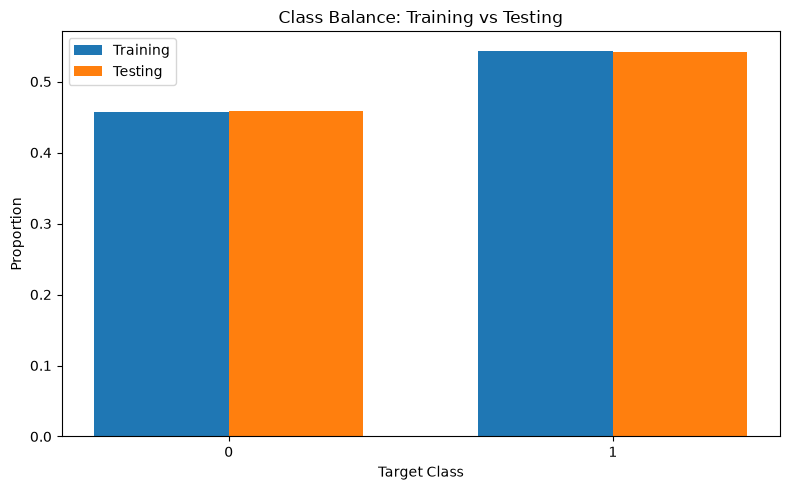

In [5]:
train_props = y_train.value_counts(normalize=True).sort_index()
test_props = y_test.value_counts(normalize=True).sort_index()

classes = sorted(y.unique())
x_positions = np.arange(len(classes))
bar_width = 0.35

plt = __import__("matplotlib.pyplot", fromlist=["pyplot"])

plt.figure(figsize=(8, 5))

plt.bar(
    x_positions - bar_width / 2,
    [train_props.get(c, 0) for c in classes],
    bar_width,
    label="Training"
)

plt.bar(
    x_positions + bar_width / 2,
    [test_props.get(c, 0) for c in classes],
    bar_width,
    label="Testing"
)

plt.xticks(x_positions, [str(c) for c in classes])
plt.xlabel("Target Class")
plt.ylabel("Proportion")
plt.title("Class Balance: Training vs Testing")
plt.legend()
plt.tight_layout()
plt.show()

## Conclusion

The dataset was divided into training and testing sets using a custom
stratified splitting function. Each target class was shuffled separately
before splitting, helping preserve class proportions in both sets.
The split was verified by comparing sample counts and class proportions.

Small differences in the exact 80:20 ratio can occur because each class
contains a whole number of records.